# Ajustes NOGSE en función de $x$ (AUTOX) con el piso de ruido de la magnitud restado

Compañero de `nogse_fits_autox.ipynb`, como `nogse_fits_trapezoidal_lobes_noise_floor.ipynb` lo es del notebook en $G$: mismos datos, mismo modelo (lóbulos trapezoidales, $b$ exacto) y mismo ajuste de un solo $D_0$ con $M_0=1$. **La única diferencia es que antes de ajustar se resta el piso de ruido de la magnitud** de las señales normalizadas. El ajuste sin corregir se repite al lado para compararlos. Salidas en `signal_analysis/results/autox_noise_floor/sub-<SUB>/ses-<SESSION_ID>/`.

## Corrección

Con $S=\sqrt{A^2+F^2}$ para la señal media del ROI ($F$ = piso, unidades del escáner) aplicado a $S$ y a $S_0$,

$$a=\frac{A}{A_0}=\frac{\sqrt{\max(S^2-F^2,\,0)}}{\sqrt{S_0^2-F^2}}.$$

## De dónde sale $F$

Un barrido en $x$ a $T=50$ ms y $G\le30$ mT/m no atenúa el agua lo suficiente para ver el piso (en agua $S/S_0\ge0.18$). Por eso $F$ se mide en la **sesión AUTOG del mismo fantoma** (mismo día, misma bobina y mismo receptor), con el método del notebook de piso en $G$: (1) un $D_0$ de referencia ajustando $e^{-bD_0}$ a los puntos de agua con $s\ge$ `FLOOR_FREE_MIN_SIGNAL`; (2) puntos de meseta, cuya atenuación predicha es menor que `PLATEAU_MAX_SIGNAL` (Hahn y CPMG largos a $G$ alto); (3) $F$ = media de `value` en esos puntos. Se puede imponer un valor con `FLOOR_F_OVERRIDE`.

El piso depende de la posición (sensibilidad de las bobinas), así que un único $F$ es una aproximación; la tabla lo da por ROI de agua para ver cuánto cambia.

**Por qué importa aquí.** En PHANTOM-3 el piso es $\approx17$ unidades y `fiber2` tiene $S_0\approx21$: esa ROI está casi entera sobre el piso, su $S/S_0$ medido casi no baja con $G$, y solo la versión corregida tiene sentido (con un error grande).

## Qué datos entran y de dónde sale cada parámetro

Cada fila de `master.long.parquet` es la señal de un volumen en un ROI. Se usan las filas del barrido en $x$ (`type = AUTOX`, o un protocolo `<D>dir<X>x`) del sujeto y la sesión elegidos, `stat = avg`, sin los dos b0.

| Columna | Símbolo | Qué es | De dónde viene |
|---|---|---|---|
| `value` | $S(x)$ | media de la señal en el ROI (máscara manual) del volumen | `signal_extraction` sobre el NIfTI (`raw` o `den_gr`) |
| `S0`, `value_norm` | $S_0$, $M=S/S_0$ | $S_0$ es la media de los dos b0 de la **misma** serie (mismo $G$) | ingest de `signal_analysis` |
| `TN` | $T$ | duración del bloque NOGSE, 50 ms; también `td_ms` | `sequence_parameters_phantoms.xlsx` |
| `N` | $N$ | número de períodos, 2 | ídem |
| `G` | $G$ | amplitud **fija** de la serie: 10, 20 o 30 mT/m (una serie por $G$) | ídem |
| `ramp_time_ms` | $t_r$ | rampa de cada trapecio, 0.32 ms | ídem |
| `bvalue` | $b$ | b-value exacto del `.bval` | `.bval` de BIDS |
| `x` | $x$ | período CPMG de **cada volumen** (ms): de $0$ (Hahn puro) a $T/N$ (CPMG) en 20 pasos | ingest (`add_x_sweep_derivatives`): invierte $b/G^2 = k_{trap}(T,N,x,t_r)$ |
| `y` | $y$ | período Hahn, $y=T-(N-1)x$ | ídem |
| `direction` | — | eje del gradiente: 1 = $x$, 2 = $y$, 3 = $z$ | `.bvec` |

Los $x$ jugables son $0$ y $[4t_r,\ T/N]$ (cada medio lóbulo contiene dos rampas): entre $0$ y $4t_r = 1.28$ ms no hay forma de onda posible, por eso las curvas del modelo se dibujan en $[4t_r, T/N]$ y el valor en $x=0$ como un rombo abierto.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'Data-BIDS').is_dir() and (candidate / 'repos' / 'signal_analysis').is_dir():
            return candidate
    raise FileNotFoundError('No encuentro la raíz del proyecto.')


PROJECT_ROOT = find_project_root()
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from data_processing.result_signals import X_SWEEP_NAME
from fitting.b_from_g import nogse_trapezoid_b_per_g2
from models.model_fitting import _GYRO

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
PROJECT_ROOT

PosixPath('/mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE')

## Configuración

Igual que `nogse_fits_autox.ipynb`, más la sesión y los ROIs de los que se mide el piso.

In [2]:
OUTPUT_NAME = 'autox_noise_floor'
ANALYSIS_TAG = 'den_gr--manual'  # alternativa: 'raw--manual'
SUB = 'PHANTOM-3'
SESSION_ID = '20261026NOGSEV2003FOV220M128SL01R1AUTOX'
ROIS = None  # p. ej. ['water1', 'water2']; None: todos los ROIs del barrido
STAT = 'avg'
D0_BOUNDS_MM2_S = (1e-4, 1e-2)
FIT_M0 = True  # False: M0 = 1 fixed, exactly as in the G notebooks

FLOOR_SESSION_ID = '20261026NOGSEV2001FOV220M128SL01R1G070AUTOG'  # session with the floor plateau
FLOOR_ROIS = ['water1', 'water2']
FLOOR_FREE_MIN_SIGNAL = 0.2  # reference D0 only from points with S/S0 >= 0.2
PLATEAU_MAX_SIGNAL = 0.003   # plateau points: predicted attenuation below 0.3 %
FLOOR_F_OVERRIDE = None      # scanner units; None: measured from FLOOR_SESSION_ID

MASTER_PATH = (PROJECT_ROOT / 'Data-BIDS' / 'derivatives' / 'signal_analysis' /
               ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet')
OUTPUT_ROOT = REPO_ROOT / 'results' / OUTPUT_NAME / f'sub-{SUB}' / f'ses-{SESSION_ID}'
SIGNAL_DIR = OUTPUT_ROOT / 'signals'
CONTRAST_DIR = OUTPUT_ROOT / 'contrasts'
SUMMARY_DIR = OUTPUT_ROOT / 'summary'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (SIGNAL_DIR, CONTRAST_DIR, SUMMARY_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

NUMERIC = ['td_ms', 'TN', 'N', 'x', 'y', 'G', 'g', 'ramp_time_ms', 'bvalue', 'b_step', 'value', 'S0', 'value_norm']
master = pd.read_parquet(MASTER_PATH)
is_sweep = (master['type'].astype(str).str.strip().str.upper().eq('AUTOX')
            | master['protocol'].astype(str).str.contains(X_SWEEP_NAME))
available = sorted(set(master.loc[is_sweep, ['subj', 'session_id']].astype(str).itertuples(index=False, name=None)))
data = master.loc[is_sweep & (master['subj'].astype(str) == SUB) &
                  (master['session_id'].astype(str) == SESSION_ID) &
                  (master['stat'].astype(str) == STAT)].copy()
if ROIS is not None:
    data = data.loc[data['roi'].astype(str).isin(ROIS)]
for column in NUMERIC:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data = data.loc[data['b_step'] > 0].dropna(subset=NUMERIC)  # the b0 volumes have no x
if data.empty:
    raise ValueError(f'No hay barridos en x para SUB={SUB!r}, SESSION_ID={SESSION_ID!r}. Disponibles (subj, session_id): {available}')
data['roi'] = data['roi'].astype(str)
data['direction'] = data['direction'].astype(str)
if not np.allclose(data['TN'], data['td_ms']):
    raise ValueError('TN y td_ms no coinciden: revisar la tabla de parámetros.')
if not np.allclose(data['g'], data['G']):
    raise ValueError('En un barrido en x el g de cada volumen pesado debe ser el G de la serie.')

print('Sujeto:', SUB, '| sesión:', SESSION_ID, '| tag:', ANALYSIS_TAG)
print('Master:', MASTER_PATH)
print('Salida:', OUTPUT_ROOT)
display(data.groupby(['roi', 'G']).agg(
    n_points=('x', 'size'), n_x=('x', 'nunique'), x_min_ms=('x', 'min'), x_max_ms=('x', 'max'),
    TN_ms=('TN', 'first'), ramp_ms=('ramp_time_ms', 'first'), S0=('S0', 'first')).reset_index())

Sujeto: PHANTOM-3 | sesión: 20261026NOGSEV2003FOV220M128SL01R1AUTOX | tag: den_gr--manual
Master: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/Data-BIDS/derivatives/signal_analysis/den_gr--manual/phantoms/nogse_experiments/master.long.parquet
Salida: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autox_noise_floor/sub-PHANTOM-3/ses-20261026NOGSEV2003FOV220M128SL01R1AUTOX


,roi,G,n_points,n_x,x_min_ms,x_max_ms,TN_ms,ramp_ms,S0
0,fiber1,10.0,60,20,0.0,25.0,50.0,0.32,103.582603
1,fiber1,20.0,60,20,0.0,25.0,50.0,0.32,103.667223
2,fiber1,30.0,60,20,0.0,25.0,50.0,0.32,103.349486
3,fiber2,10.0,60,20,0.0,25.0,50.0,0.32,21.274085
4,fiber2,20.0,60,20,0.0,25.0,50.0,0.32,21.007894
5,fiber2,30.0,60,20,0.0,25.0,50.0,0.32,21.115046
6,water1,10.0,60,20,0.0,25.0,50.0,0.32,268.514124
7,water1,20.0,60,20,0.0,25.0,50.0,0.32,263.687271
8,water1,30.0,60,20,0.0,25.0,50.0,0.32,263.975727
9,water2,10.0,60,20,0.0,25.0,50.0,0.32,276.055549


## Modelo: lóbulos trapezoidales ($b$ exacto), ahora en función de $x$

Es el mismo modelo que `nogse_fits_trapezoidal_lobes.ipynb`, con los papeles cambiados: allí $x$ estaba fijo y variaba $G$; aquí $G$ está fijo en cada serie y varía $x$,

$$M(x) = M_0\,e^{-k_{trap}(T,N,x,t_r)\,G^2\,D_0},\qquad k_{trap}G^2 = b,$$

con $k_{trap}$ de `nogse_trapezoid_b_per_g2` y $\gamma$ = `_GYRO`. $k_{trap}$ es máximo en $x=0$ (Hahn puro, dos lóbulos de $T/2$) y cae hasta $x=T/N$ (CPMG), así que para difusión libre la señal **crece** con $x$.

**Ajuste.** Para cada curva (ROI, $G$, dirección) se ajusta $D_0$ minimizando el error cuadrático medio en escala lineal sobre los 20 puntos de $x$; se optimiza $\ln D_0$ en $[10^{-4},10^{-2}]$ mm²/s. Para agua libre $D_0$ no debe depender de $G$ ni de la dirección; en las fibras el $D_0$ ajustado es un coeficiente aparente.

**$M_0$ libre (`FIT_M0 = True`, por defecto).** En los notebooks en $G$ se fija $M_0=1$ porque la curva pasa por $G=0$, donde $M=1$ por construcción. Un barrido en $x$ **no tiene ningún punto con $b=0$**: todos sus puntos tienen el mismo $G$, y la normalización viene de los b0 de la serie. Cualquier factor que dependa de $G$ pero no de $x$ (en PHANTOM-3: $S/S_0$ medido ≈ 0.93, 0.82 y 0.84 veces $e^{-bD_0}$ a $G$ = 10, 20, 30 mT/m, casi constante a lo largo de $x$) se absorbería entero en $D_0$ con $M_0=1$. Con `FIT_M0 = True`, $M_0$ se ajusta junto con $D_0$ (para cada $D_0$, el $M_0$ óptimo de mínimos cuadrados, en forma cerrada) y $D_0$ queda determinado solo por la **forma** de $M(x)$. `FIT_M0 = False` reproduce exactamente el ajuste de un parámetro de los notebooks en $G$.

**Contraste.** El análogo en $x$ del contraste CPMG − Hahn es la curva respecto de su propio límite Hahn,

$$\Delta M(x) = M(x) - M(0) = e^{-k_{trap}(x)G^2D_0} - e^{-k_{trap}(0)G^2D_0},$$

calculado con los puntos de la misma serie ($x=0$ es el primer volumen pesado). En $x=T/N$ es el contraste CPMG − Hahn ideal ($x_{Hahn}=0$). Se ajusta un solo $D_0$ por (ROI, $G$, dirección), multiplicado por el $M_0$ del ajuste de la señal de esa misma curva (con $M_0$ libre también en el contraste, $M_0$ y $D_0$ se compensan y el ajuste no converge cuando la atenuación es chica).

In [3]:
def k_model(tn_ms, n_value, x_ms, ramp_ms):
    # s/mm^2 per (mT/m)^2 of the played trapezoidal waveform (exact b / G^2), one value per x
    return np.array([nogse_trapezoid_b_per_g2(N=n_value, TN_ms=tn_ms, x_ms=x, ramp_time_ms=ramp_ms, gamma=_GYRO)
                     for x in np.atleast_1d(np.asarray(x_ms, float))])


def signal_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s):
    return np.exp(-k_model(tn_ms, n_value, x_ms, ramp_ms) * float(g_mT_m)**2 * d0_mm2_s)


def contrast_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s):
    # M(x) - M(x = 0): the sweep against its own pure Hahn limit
    return (signal_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s)
            - signal_model(tn_ms, g_mT_m, n_value, 0.0, ramp_ms, d0_mm2_s))


def best_m0(y, prediction, fit_m0=None):
    # least-squares M0 for the given shape (closed form) when M0 is free; otherwise M0 = 1
    if not (FIT_M0 if fit_m0 is None else fit_m0):
        return 1.0
    return float(np.dot(y, prediction) / np.dot(prediction, prediction))


def fit_one_parameter(y, model, fit_m0=None):
    y = np.asarray(y, float)
    valid = np.isfinite(y)
    lo, hi = np.log(D0_BOUNDS_MM2_S)

    def loss(log_d0):
        prediction = np.asarray(model(np.exp(log_d0)), float)[valid]
        return np.mean((y[valid] - best_m0(y[valid], prediction, fit_m0) * prediction) ** 2)

    result = minimize_scalar(loss, bounds=(lo, hi), method='bounded')
    d0 = float(np.exp(result.x))
    prediction = np.asarray(model(d0), float)
    m0 = best_m0(y[valid], prediction[valid], fit_m0)
    residual = y[valid] - m0 * prediction[valid]
    return {
        'D0_mm2_s': d0,
        'M0': m0,
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'n_points': int(valid.sum()),
        'ok': bool(result.success),
    }


def timing(curve):
    row = curve.iloc[0]
    return float(row['TN']), float(row['N']), float(row['G']), float(row['ramp_time_ms'])


def x_playable(curve, n_points=300):
    tn_ms, n_value, _g, ramp_ms = timing(curve)
    return np.linspace(4 * ramp_ms, tn_ms / n_value, n_points)


def d0_label(d0):
    return f'$D_0$={d0 * 1e3:.3f} × 10$^{{-3}}$ mm²/s'


def save_figure(fig, folder, stem):
    fig.savefig(folder / f'{stem}.png', dpi=180, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')


def hahn_limit(curve, column):
    # value of `column` at x = 0 (pure Hahn) of one (ROI, G, direction) curve
    at_zero = curve.loc[np.isclose(curve['x'], 0.0, atol=1e-9), column]
    if len(at_zero) != 1:
        raise ValueError(f'Each curve needs exactly one x = 0 point, found {len(at_zero)}.')
    return float(at_zero.iloc[0])


direction_colors = {'1': 'tab:blue', '2': 'tab:orange', '3': 'tab:green'}
g_values = sorted(data['G'].unique())
g_colors = dict(zip(g_values, plt.cm.viridis(np.linspace(0.1, 0.8, len(g_values)))))
rois = sorted(data['roi'].unique())

def fitted(table, roi, g_value, direction, correction=None):
    rows = table.loc[table['roi'].eq(roi) & table['G'].eq(g_value) & table['direction'].eq(direction)]
    if correction is not None:
        rows = rows.loc[rows['correction'].eq(correction)]
    return rows.iloc[0]


def plot_fit_curve(ax, curve, fit, color, label, model=signal_model):
    tn_ms, n_value, g_value, ramp_ms = timing(curve)
    d0, m0 = fit['D0_mm2_s'], fit['M0']
    x_fine = x_playable(curve)
    ax.plot(x_fine, m0 * model(tn_ms, g_value, n_value, x_fine, ramp_ms, d0), color=color, lw=1.8,
            label=f'{label}: {d0_label(d0)}' + (f', $M_0$={m0:.3f}' if FIT_M0 else ''))
    ax.plot([0.0], m0 * model(tn_ms, g_value, n_value, 0.0, ramp_ms, d0), 'D', color=color, mfc='none', ms=6)


def panel_figure(n_panels, title):
    fig, axes = plt.subplots(1, n_panels, figsize=(5.0 * n_panels, 4.3), sharey=True, squeeze=False)
    fig.suptitle(title, fontsize=12)
    return fig, axes[0]

## Medida del piso

$D_0$ de referencia, atenuación predicha de cada punto de la sesión `FLOOR_SESSION_ID`, puntos de meseta y $F$. La tabla da los puntos de meseta por ROI y la dispersión de $s$ entre ellos.

In [4]:
floor_data = master.loc[(master['subj'].astype(str) == SUB) &
                        (master['session_id'].astype(str) == FLOOR_SESSION_ID) &
                        (master['stat'].astype(str) == STAT) &
                        (master['roi'].astype(str).isin(FLOOR_ROIS))].copy()
for column in ['bvalue', 'b_step', 'value', 'S0', 'value_norm', 'g', 'td_ms']:
    floor_data[column] = pd.to_numeric(floor_data[column], errors='coerce')
floor_data = floor_data.loc[floor_data['b_step'] > 0].dropna(subset=['bvalue', 'value', 'S0', 'value_norm'])

if FLOOR_F_OVERRIDE is not None:
    FLOOR_F = float(FLOOR_F_OVERRIDE)
    print(f'Floor F = {FLOOR_F:.2f} (impuesto con FLOOR_F_OVERRIDE)')
else:
    if floor_data.empty:
        raise ValueError(f'No hay filas de {FLOOR_ROIS} en la sesión {FLOOR_SESSION_ID}: definir FLOOR_F_OVERRIDE.')
    keep = floor_data['value_norm'] >= FLOOR_FREE_MIN_SIGNAL
    b_ref, s_ref = floor_data.loc[keep, 'bvalue'].to_numpy(float), floor_data.loc[keep, 'value_norm'].to_numpy(float)
    D0_REFERENCE = fit_one_parameter(s_ref, lambda d0: np.exp(-b_ref * d0), fit_m0=False)['D0_mm2_s']
    floor_data['a_predicted'] = np.exp(-floor_data['bvalue'] * D0_REFERENCE)
    plateau = floor_data.loc[floor_data['a_predicted'] < PLATEAU_MAX_SIGNAL]
    if plateau.empty:
        raise ValueError('No hay puntos de meseta: subir PLATEAU_MAX_SIGNAL o definir FLOOR_F_OVERRIDE.')
    FLOOR_F = float(plateau['value'].mean())
    print(f'D0 de referencia (s >= {FLOOR_FREE_MIN_SIGNAL}): {D0_REFERENCE * 1e3:.4f} × 1e-3 mm²/s')
    print(f'Floor F = {FLOOR_F:.2f} (unidades del escáner) de {len(plateau)} puntos de meseta')
    display(plateau.groupby(['roi', 'type', 'td_ms']).agg(
        n=('value', 'size'), g_min=('g', 'min'), a_predicted_max=('a_predicted', 'max'),
        value_mean=('value', 'mean'), s_mean=('value_norm', 'mean'), s_sd=('value_norm', 'std')).reset_index())

data['c_floor'] = FLOOR_F / data['S0']
data['value_norm_corr'] = (np.sqrt(np.clip(data['value']**2 - FLOOR_F**2, 0, None)) /
                           np.sqrt(np.clip(data['S0']**2 - FLOOR_F**2, 0, None)))
floor_table = data.groupby(['roi', 'G']).agg(S0=('S0', 'first'), c_floor=('c_floor', 'first'),
                                             n_below_floor=('value', lambda v: int((v < FLOOR_F).sum()))).reset_index()
floor_table.insert(0, 'F_scanner_units', FLOOR_F)
floor_table.to_csv(TABLE_DIR / 'noise_floor.csv', index=False)
display(floor_table)
if (floor_table['c_floor'] > 0.5).any():
    print('ATENCIÓN: ROIs con F/S0 > 0.5 — la señal está casi entera sobre el piso y la corrección amplifica el ruido:',
          sorted(floor_table.loc[floor_table['c_floor'] > 0.5, 'roi'].unique()))

D0 de referencia (s >= 0.2): 3.0938 × 1e-3 mm²/s
Floor F = 16.75 (unidades del escáner) de 42 puntos de meseta


,roi,type,td_ms,n,g_min,a_predicted_max,value_mean,s_mean,s_sd
0,water1,HAHN,50.0,6,63.0,0.002159,17.311839,0.064373,0.000745
1,water1,HAHN,65.0,15,42.0,0.001351,17.223889,0.064328,0.000712
2,water2,HAHN,50.0,6,63.0,0.002159,16.325784,0.060545,0.000423
3,water2,HAHN,65.0,15,42.0,0.001351,16.227721,0.060212,0.000322


,F_scanner_units,roi,G,S0,c_floor,n_below_floor
0,16.752379,fiber1,10.0,103.582603,0.161730,0
1,16.752379,fiber1,20.0,103.667223,0.161598,0
2,16.752379,fiber1,30.0,103.349486,0.162094,0
3,16.752379,fiber2,10.0,21.274085,0.787455,0
4,16.752379,fiber2,20.0,21.007894,0.797433,0
5,16.752379,fiber2,30.0,21.115046,0.793386,0
6,16.752379,water1,10.0,268.514124,0.062389,0
7,16.752379,water1,20.0,263.687271,0.063531,0
8,16.752379,water1,30.0,263.975727,0.063462,0
9,16.752379,water2,10.0,276.055549,0.060685,0


ATENCIÓN: ROIs con F/S0 > 0.5 — la señal está casi entera sobre el piso y la corrección amplifica el ruido: ['fiber2']


## Ajustes: sin corregir y con el piso restado

Los mismos ajustes que `nogse_fits_autox.ipynb`, una vez con `value_norm` y otra con `value_norm_corr`. En las figuras: puntos llenos = corregidos (con su ajuste), abiertos grises = medidos.

correction   floor_removed  uncorrected
roi    G                               
fiber1 10.0         1.4643       1.4206
       20.0         1.4747       1.4041
       30.0         1.4486       1.3157
fiber2 10.0         3.9768       1.1131
       20.0         1.7099       0.2900
       30.0         1.1077       0.1239
water1 10.0         2.5877       2.5738
       20.0         2.1149       2.0881
       30.0         2.1535       2.0903
water2 10.0         2.2672       2.2556
       20.0         1.9309       1.9086
       30.0         2.1319       2.0745

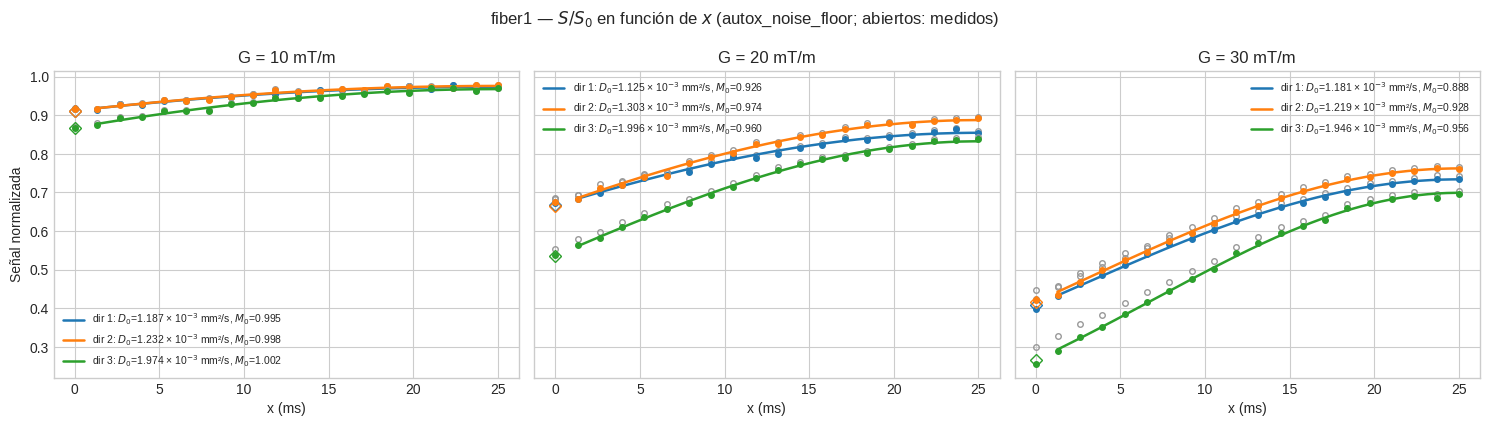

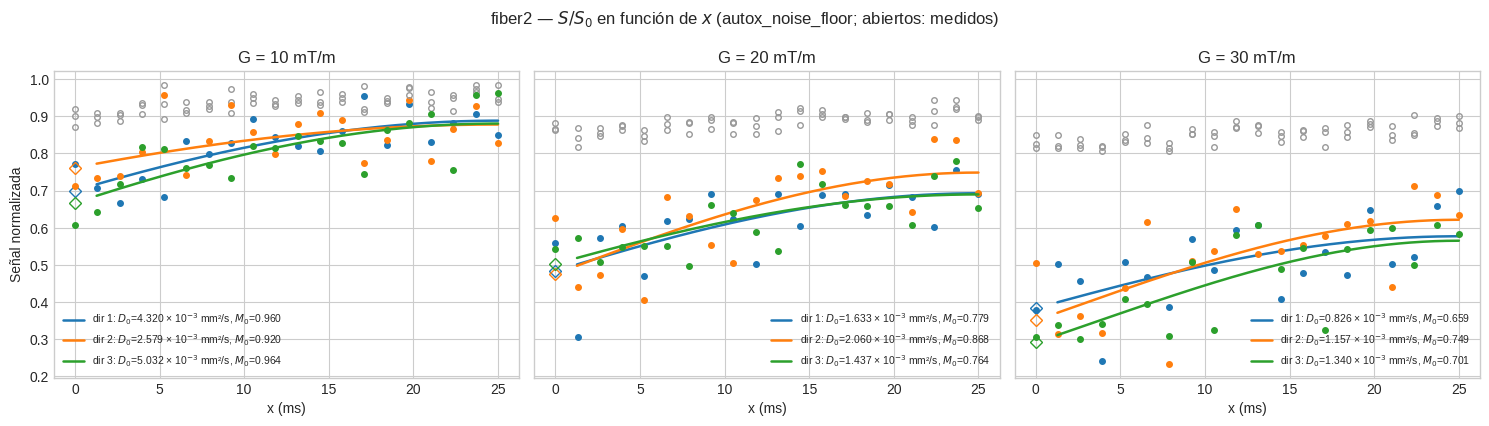

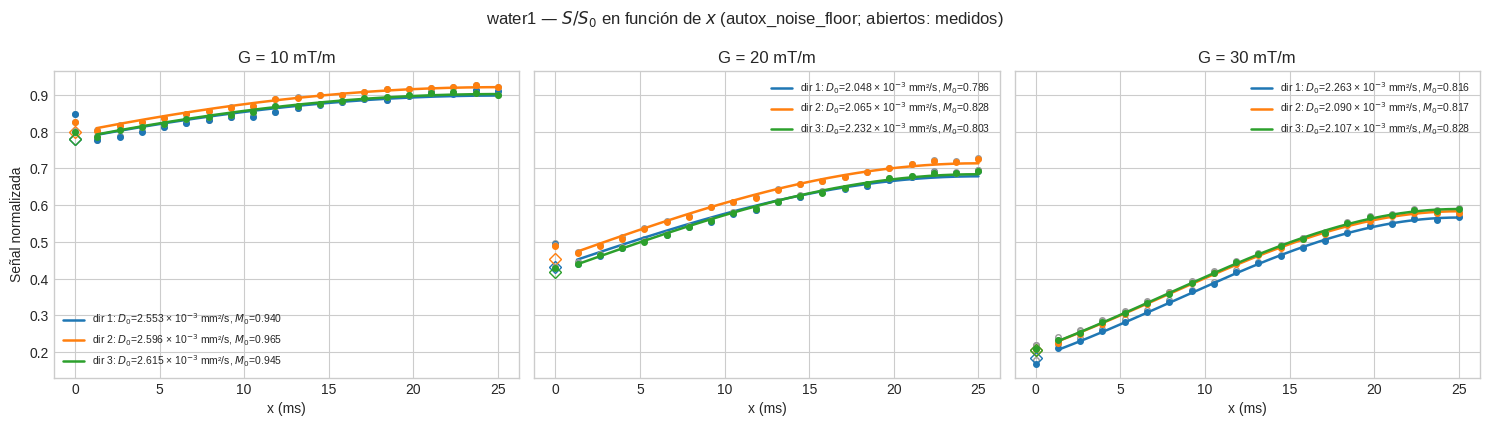

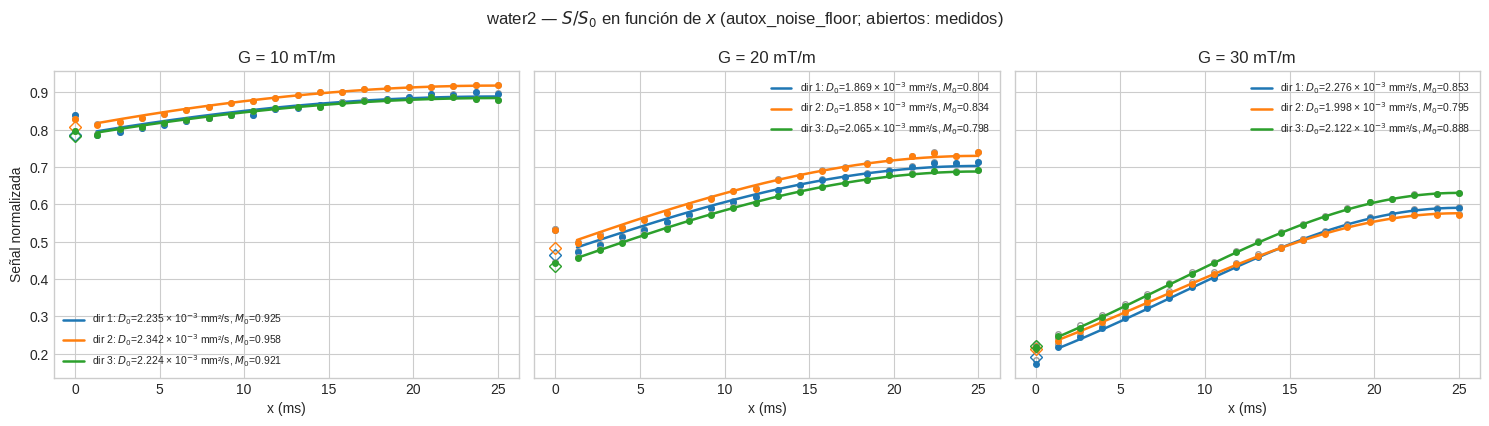

In [5]:
DATA_COLUMNS = {'uncorrected': 'value_norm', 'floor_removed': 'value_norm_corr'}

signal_fit_rows = []
for (roi, g_value, direction), curve in data.groupby(['roi', 'G', 'direction'], sort=True):
    curve = curve.sort_values('x')
    tn_ms, n_value, _g, ramp_ms = timing(curve)
    k = k_model(tn_ms, n_value, curve['x'], ramp_ms)
    for correction, column in DATA_COLUMNS.items():
        fit = fit_one_parameter(curve[column], lambda d0: np.exp(-k * g_value**2 * d0))
        signal_fit_rows.append({
            'model': 'trapezoidal_lobes', 'correction': correction, 'analysis_tag': ANALYSIS_TAG, 'subj': SUB,
            'session_id': SESSION_ID, 'roi': roi, 'G': g_value, 'direction': direction, 'TN': tn_ms, 'N': n_value,
            'ramp_ms': ramp_ms, 'floor_F': FLOOR_F, **fit
        })

signal_fits = pd.DataFrame(signal_fit_rows).sort_values(['correction', 'roi', 'G', 'direction'])
signal_fits.to_csv(TABLE_DIR / 'signal_fits.csv', index=False)
display(signal_fits.pivot_table(index=['roi', 'G'], columns='correction', values='D0_mm2_s', aggfunc='mean').mul(1e3).round(4))

for roi in rois:
    fig, axes = panel_figure(len(g_values), f'{roi} — $S/S_0$ en función de $x$ ({OUTPUT_NAME}; abiertos: medidos)')
    for ax, g_value in zip(axes, g_values):
        for direction, curve in data.loc[data['roi'].eq(roi) & data['G'].eq(g_value)].groupby('direction', sort=True):
            curve = curve.sort_values('x')
            color = direction_colors.get(direction)
            ax.plot(curve['x'], curve['value_norm'], 'o', color='0.6', mfc='none', ms=4)
            ax.plot(curve['x'], curve['value_norm_corr'], 'o', color=color, ms=4)
            plot_fit_curve(ax, curve, fitted(signal_fits, roi, g_value, direction, 'floor_removed'), color, f'dir {direction}')
        ax.set(title=f'G = {g_value:g} mT/m', xlabel='x (ms)')
        ax.legend(fontsize=7.5)
    axes[0].set_ylabel('Señal normalizada')
    fig.tight_layout()
    save_figure(fig, SIGNAL_DIR, f'signal_{roi}_by-direction')
    plt.show()

## Contraste respecto del límite Hahn

$\Delta M(x) = M(x)-M(0)$ medido (`value_contrast`) y corregido (`value_contrast_corr`).

correction   floor_removed  uncorrected
roi    G                               
fiber1 10.0         1.4047       1.3620
       20.0         1.4182       1.3426
       30.0         1.5169       1.3065
fiber2 10.0         4.6358       1.1706
       20.0         0.7161       0.1448
       30.0         0.7436       0.1037
water1 10.0         1.5080       1.5002
       20.0         1.5964       1.5757
       30.0         2.1378       2.0557
water2 10.0         1.4157       1.4086
       20.0         1.4249       1.4080
       30.0         2.1830       2.1085

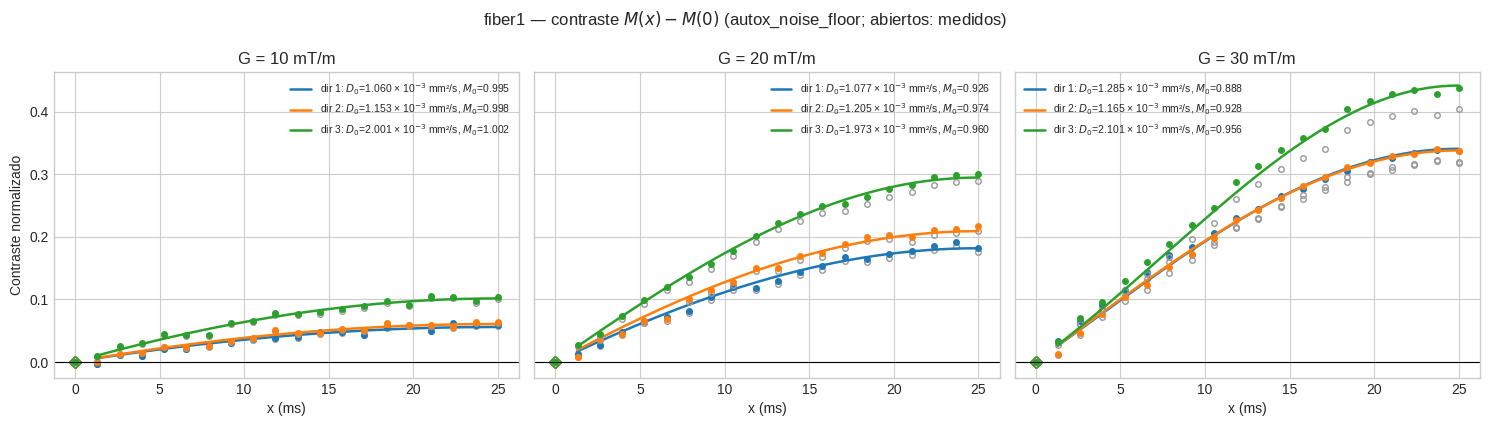

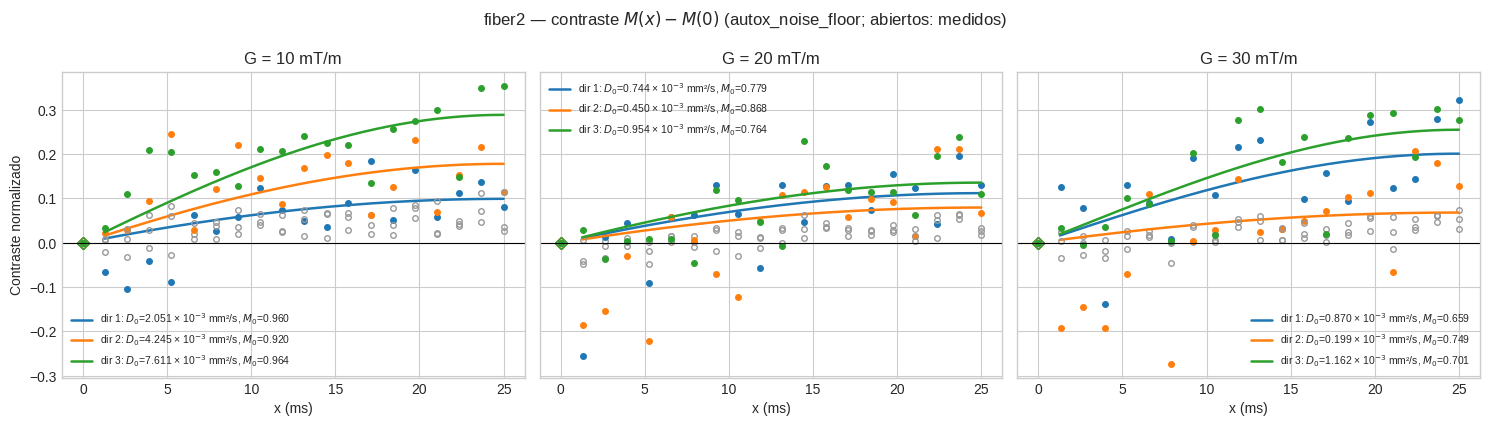

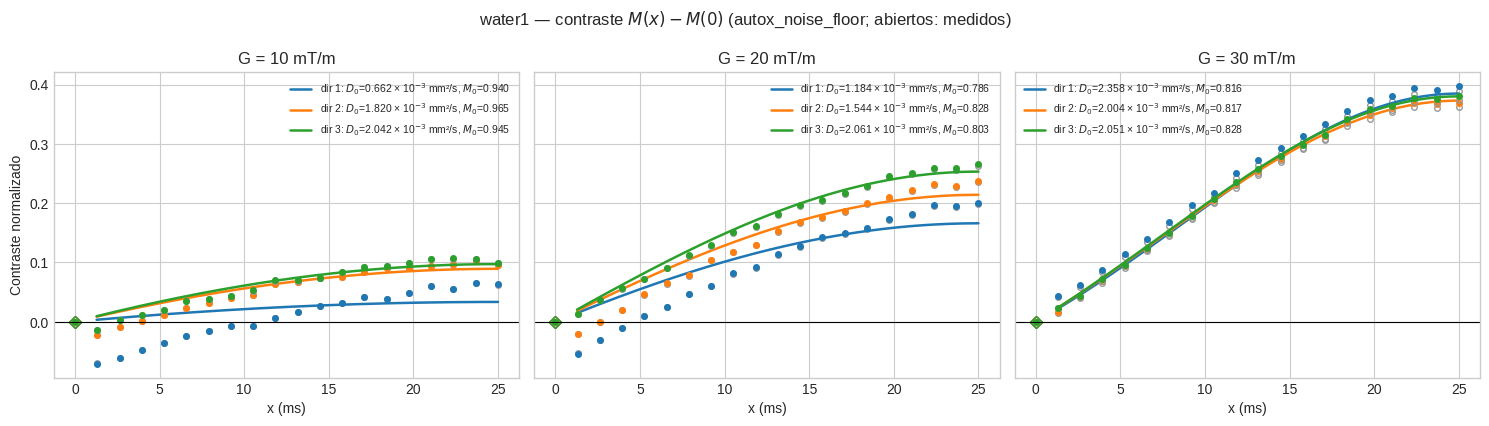

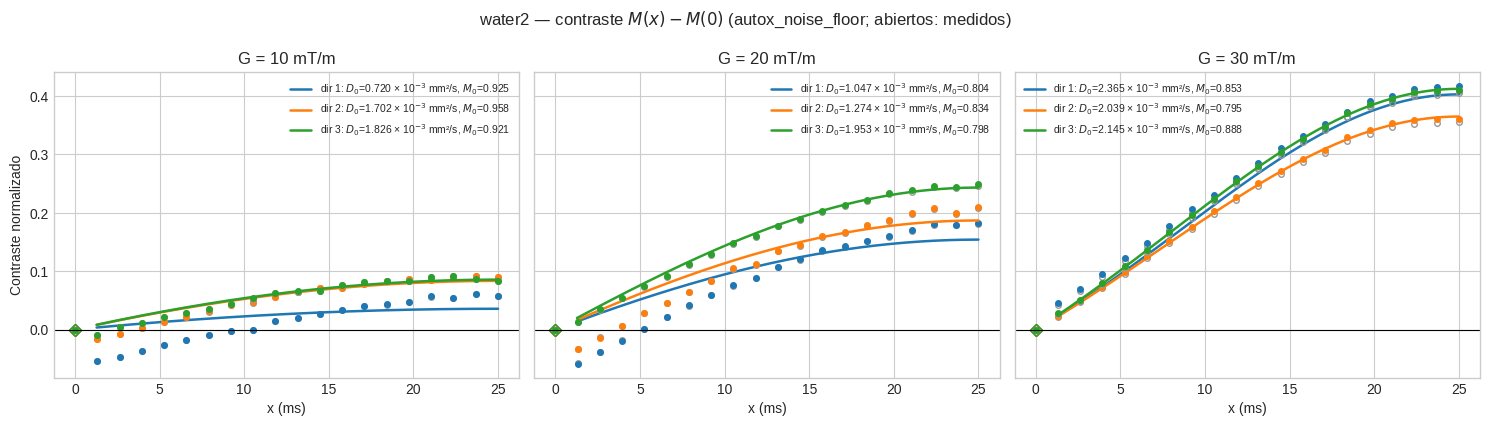

In [6]:
CONTRAST_COLUMNS = {'uncorrected': 'value_contrast', 'floor_removed': 'value_contrast_corr'}
for correction, column in DATA_COLUMNS.items():
    data[CONTRAST_COLUMNS[correction]] = data[column] - data.groupby(['roi', 'G', 'direction'])[column].transform(
        lambda s, column=column: hahn_limit(data.loc[s.index], column))

contrast_fit_rows = []
for (roi, g_value, direction), curve in data.groupby(['roi', 'G', 'direction'], sort=True):
    curve = curve.sort_values('x')
    tn_ms, n_value, _g, ramp_ms = timing(curve)
    k = k_model(tn_ms, n_value, curve['x'], ramp_ms)
    k0 = k_model(tn_ms, n_value, 0.0, ramp_ms)
    for correction, column in CONTRAST_COLUMNS.items():
        m0 = fitted(signal_fits, roi, g_value, direction, correction)['M0']  # M0 of the signal fit, D0 only
        fit = fit_one_parameter(curve[column],
                                lambda d0: m0 * (np.exp(-k * g_value**2 * d0) - np.exp(-k0 * g_value**2 * d0)),
                                fit_m0=False)
        fit['M0'] = m0
        contrast_fit_rows.append({
            'model': 'trapezoidal_lobes', 'correction': correction, 'analysis_tag': ANALYSIS_TAG, 'subj': SUB,
            'session_id': SESSION_ID, 'roi': roi, 'G': g_value, 'direction': direction,
            'contrast_at_x_max': float(curve[column].iloc[-1]), **fit
        })

contrast_fits = pd.DataFrame(contrast_fit_rows).sort_values(['correction', 'roi', 'G', 'direction'])
contrast_fits.to_csv(TABLE_DIR / 'contrast_fits.csv', index=False)
display(contrast_fits.pivot_table(index=['roi', 'G'], columns='correction', values='D0_mm2_s', aggfunc='mean').mul(1e3).round(4))

for roi in rois:
    fig, axes = panel_figure(len(g_values), f'{roi} — contraste $M(x)-M(0)$ ({OUTPUT_NAME}; abiertos: medidos)')
    for ax, g_value in zip(axes, g_values):
        for direction, curve in data.loc[data['roi'].eq(roi) & data['G'].eq(g_value)].groupby('direction', sort=True):
            curve = curve.sort_values('x')
            color = direction_colors.get(direction)
            ax.plot(curve['x'], curve['value_contrast'], 'o', color='0.6', mfc='none', ms=4)
            ax.plot(curve['x'], curve['value_contrast_corr'], 'o', color=color, ms=4)
            plot_fit_curve(ax, curve, fitted(contrast_fits, roi, g_value, direction, 'floor_removed'), color,
                           f'dir {direction}', model=contrast_model)
        ax.axhline(0, color='k', lw=0.8)
        ax.set(title=f'G = {g_value:g} mT/m', xlabel='x (ms)')
        ax.legend(fontsize=7.5)
    axes[0].set_ylabel('Contraste normalizado')
    fig.tight_layout()
    save_figure(fig, CONTRAST_DIR, f'contrast_{roi}')
    plt.show()

## Resumen: $D_0$ en función de $G$, sin corregir y corregido

Media de las tres direcciones (×10⁻³ mm²/s). Para agua libre $D_0$ no debe depender de $G$; si el piso sesgaba el ajuste, la versión corregida debe ser más plana (`CV_over_G_%` menor). A la derecha, todas las series contra el $b$ exacto con el piso restado.

G                       10.0    20.0    30.0  CV_over_G_%
correction    roi                                        
floor_removed fiber1  1.4643  1.4747  1.4486       0.9002
              fiber2  3.9768  1.7099  1.1077      66.8002
              water1  2.5877  2.1149  2.1535      11.4883
              water2  2.2672  1.9309  2.1319       8.0218
uncorrected   fiber1  1.4206  1.4041  1.3157       4.0865
              fiber2  1.1131  0.2900  0.1239     104.0802
              water1  2.5738  2.0881  2.0903      12.4299
              water2  2.2556  1.9086  2.0745       8.3470

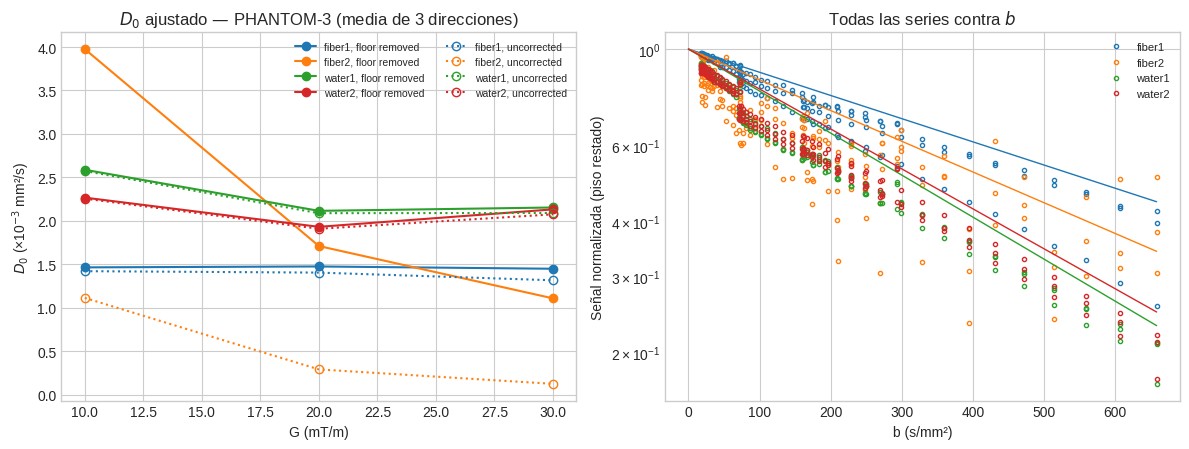

Figuras y tablas guardadas en: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autox_noise_floor/sub-PHANTOM-3/ses-20261026NOGSEV2003FOV220M128SL01R1AUTOX


In [7]:
summary = signal_fits.groupby(['correction', 'roi', 'G'])['D0_mm2_s'].mean().mul(1e3).unstack('G')
summary['CV_over_G_%'] = 100 * summary.std(axis=1, ddof=1) / summary.mean(axis=1)
summary.to_csv(TABLE_DIR / 'D0_summary_1e-3_mm2_s.csv')
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6))
for (correction, roi), row in summary.drop(columns='CV_over_G_%').iterrows():
    color = plt.cm.tab10.colors[rois.index(roi) % 10]
    axes[0].plot(row.index, row.to_numpy(), 'o', color=color, ls='-' if correction == 'floor_removed' else ':',
                 mfc=color if correction == 'floor_removed' else 'none', label=f'{roi}, {correction.replace("_", " ")}')
axes[0].set(xlabel='G (mT/m)', ylabel='$D_0$ (×10$^{-3}$ mm²/s)', title=f'$D_0$ ajustado — {SUB} (media de 3 direcciones)')
axes[0].legend(fontsize=7.5, ncol=2)

b_fine = np.linspace(0, data['bvalue'].max(), 300)
for roi, color in zip(rois, plt.cm.tab10.colors):
    points = data.loc[data['roi'].eq(roi)]
    axes[1].semilogy(points['bvalue'], points['value_norm_corr'].clip(lower=1e-3), 'o', color=color, ms=3, mfc='none',
                     label=roi)
    d0_roi = signal_fits.loc[signal_fits['roi'].eq(roi) & signal_fits['correction'].eq('floor_removed'), 'D0_mm2_s'].median()
    axes[1].semilogy(b_fine, np.exp(-b_fine * d0_roi), '-', color=color, lw=1)
axes[1].set(xlabel='b (s/mm²)', ylabel='Señal normalizada (piso restado)', title='Todas las series contra $b$')
axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, SUMMARY_DIR, 'D0_vs_G_and_signal_vs_b')
plt.show()
print('Figuras y tablas guardadas en:', OUTPUT_ROOT)